# Univariate data - Geospatial

This tutorial covers the `GeoUnivar` object, a `Univar` whose values have a location. It adds a map panel to the standard visual, next to the data, the histogram and the CDF.

```{seealso}
Check out the {doc}`Univariate data - Basics <univar_01>` and {doc}`Univariate data - Plots <univar_02_plots>` tutorials first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
from pathlib import Path
import numpy as np
import geopandas as gpd
from shapely.geometry import Polygon

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.datasets.analyst import GeoUnivar
from plans.stochastic.binning import get_bins

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/geounivar")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\geounivar


## Sample data

Lets make all the data from scratch with `geopandas`, using geographic coordinates. First, a catchment, as a single polygon. Its outline is a circle, with a radius that varies around the center:

In [2]:
rng = np.random.default_rng(seed=1)  # ensure reproducibility

angle = np.linspace(start=0, stop=2 * np.pi, num=60, endpoint=False)
radius = 0.2 + 0.05 * np.sin(3 * angle) + 0.025 * np.cos(7 * angle + 1)
x = -51.2 + 1.3 * radius * np.cos(angle)
y = -30.1 + radius * np.sin(angle)

catchment = gpd.GeoDataFrame(
    data={"name": ["Catchment"]},
    geometry=[Polygon(shell=list(zip(x, y)))],
    crs="EPSG:4674",
)
catchment

,name,geometry
0,Catchment,"POLYGON ((-50.92244 -30.1, -50.92667 -30.0779,..."


Next, the points: soil samples at random locations. They are drawn over the bounding box of the catchment, and only those within the polygon are kept:

In [3]:
xmin, ymin, xmax, ymax = catchment.total_bounds

points = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(
        x=rng.uniform(low=xmin, high=xmax, size=600),
        y=rng.uniform(low=ymin, high=ymax, size=600),
        crs="EPSG:4674",
    )
)
points = points[points.within(other=catchment.geometry.iloc[0])].reset_index(drop=True)
print(f"{len(points)} points")

417 points


Each sample gets a value of soil organic carbon. Values rise to the east, with some skewed noise, so the map has a pattern to show:

In [4]:
east = (points.geometry.x - xmin) / (xmax - xmin)
points["soc"] = 1 + 3 * east + rng.gamma(shape=2, scale=0.4, size=len(points))
points.head()

,geometry,soc
0,POINT (-51.20624 -30.24392),3.770107
1,POINT (-51.42191 -30.01331),1.750928
2,POINT (-50.94999 -29.93546),5.514472
3,POINT (-51.32355 -30.2484),3.417389
4,POINT (-51.25815 -30.27589),2.367847


## Setting the data

A `GeoUnivar` holds a `GeoDataFrame` in its `.data` attribute. The `.set_data()` method takes the `GeoDataFrame` and the name of the column of values. It keeps only the values and the geometry, in a new table, and drops rows with missing values:

In [5]:
gv = GeoUnivar(name="Soil Carbon", alias="SOC")
gv.varname = "Soil Organic Carbon"
gv.units = "%"
gv.set_data(input_df=points, input_varfield="soc")
gv.data.head()

,v,geometry
0,3.770107,POINT (-51.20624 -30.24392)
1,1.750928,POINT (-51.42191 -30.01331)
2,5.514472,POINT (-50.94999 -29.93546)
3,3.417389,POINT (-51.32355 -30.2484)
4,2.367847,POINT (-51.25815 -30.27589)


Statistics work as in `Univar`:

In [6]:
gv.stats_df

,statistic,value
0,count,417.000000
1,sum,1413.427918
2,mean,3.389515
3,sd,0.929507
4,min,1.312094
5,p01,1.538221
6,p05,1.932009
7,p10,2.237571
8,p20,2.550812
9,p25,2.684995


## Standard visualization

Get the standard visual using the `.view()` method. Colors on the map follow classes of value, shown as the color bars beside the data and histogram panels. The map panel is always square and aligned with the top of the other panels, so its view limits widen to fit the shape of the data:

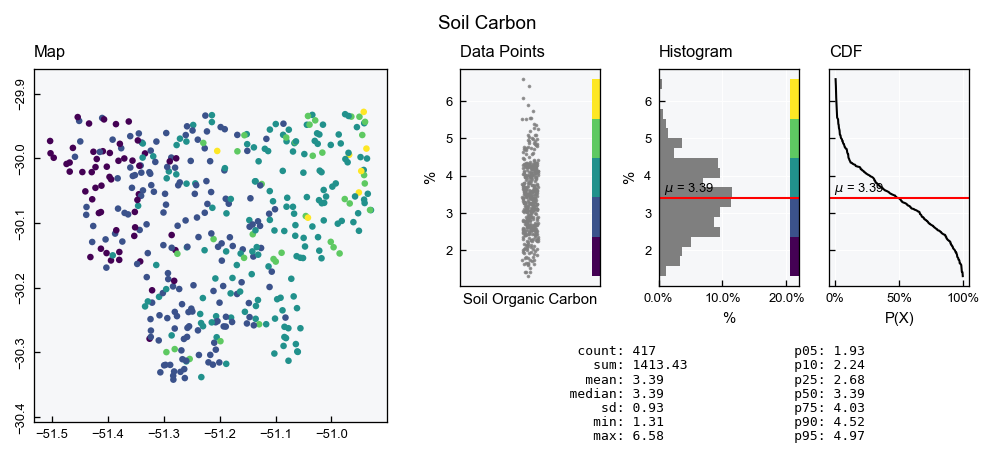

In [7]:
gv.view()

`GeoUnivar` has two layouts:

In [8]:
print(gv.layouts.keys())

dict_keys(['full', 'mini'])


The `mini` layout has a smaller map and drops the statistics table:

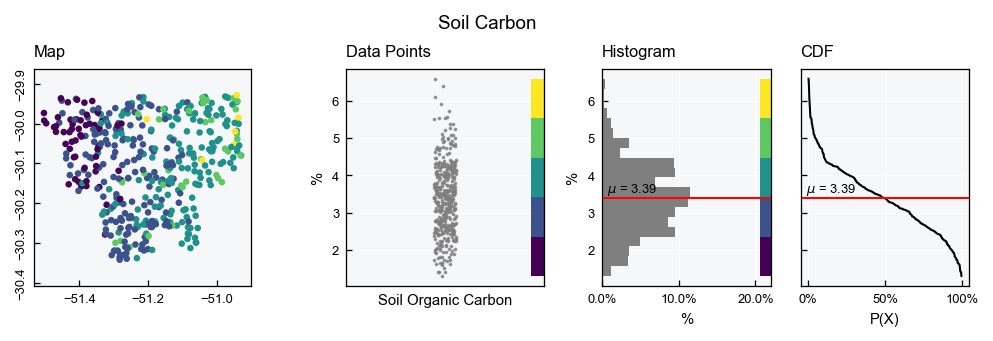

In [9]:
gv.view_specs["layout"] = "mini"
gv.view()

## Fine-tuning the classes

Colors follow classes of value, five by default, and the `scheme_cmap` key sets how they are defined. There are two options, and `get_bins()` shows the boundaries each one gives for this sample:

In [10]:
vct_values = gv.data[gv.varfield].values
for scheme in ["equal", "quantiles"]:
    bins = get_bins(data=vct_values, n_bins=5, scheme=scheme)
    print(f"{scheme:>9}: {np.round(bins, 2)}")

    equal: [1.31 2.37 3.42 4.47 5.53 6.58]
quantiles: [1.31 2.55 3.12 3.59 4.17 6.58]


`equal` is the default, with classes of the same width. It keeps the scale of the values, so high values stand out, but most points fall in the middle classes:

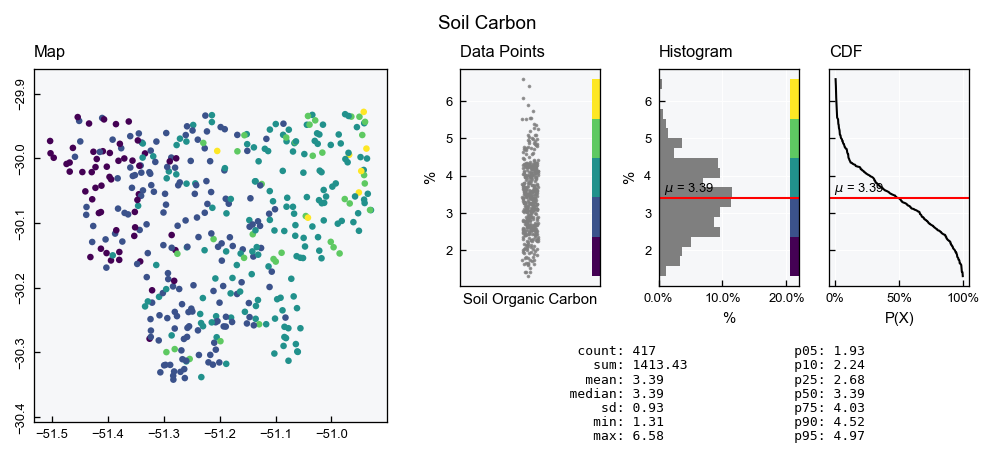

In [11]:
gv.view_specs["layout"] = "full"
gv.view_specs["scheme_cmap"] = "equal"
gv.view()

`quantiles` makes classes with the same number of points. All colors are used evenly, so the west to east pattern is clearer, but classes have different widths, as the color bars show:

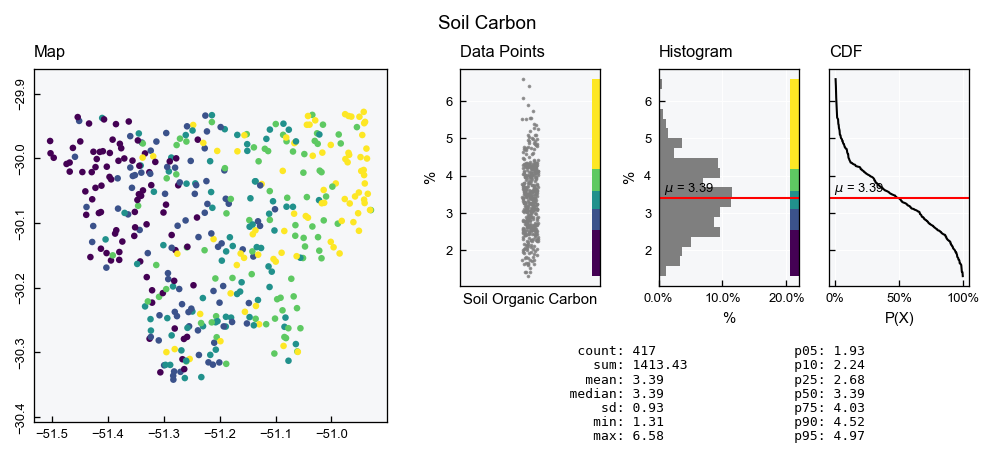

In [12]:
gv.view_specs["scheme_cmap"] = "quantiles"
gv.view()

The `n_classes_cmap` key sets the number of classes. Fewer classes give a simpler map, and the panels and color bars all follow:

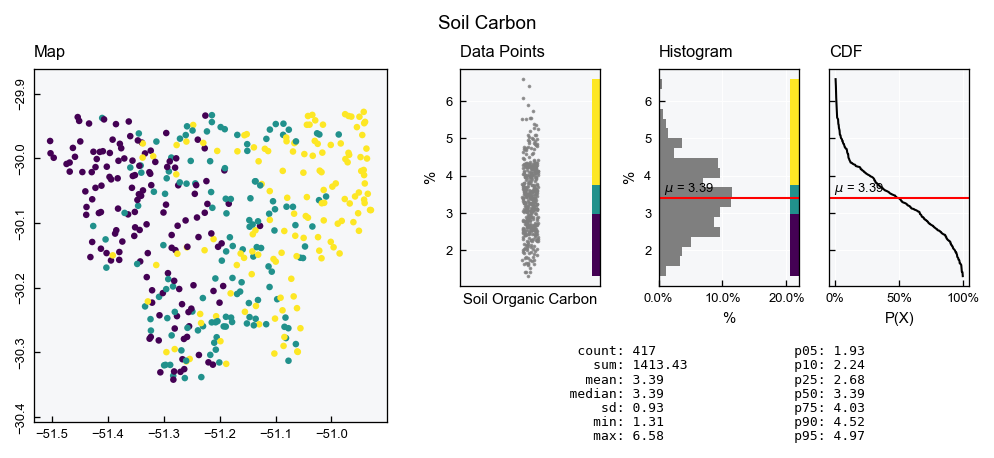

In [13]:
gv.view_specs["n_classes_cmap"] = 3
gv.view()

The `cmap` key sets the colors, with any `matplotlib` color map name. Other map options are the keys ending in `_map`, such as `marker_map` and `markersize_map`:

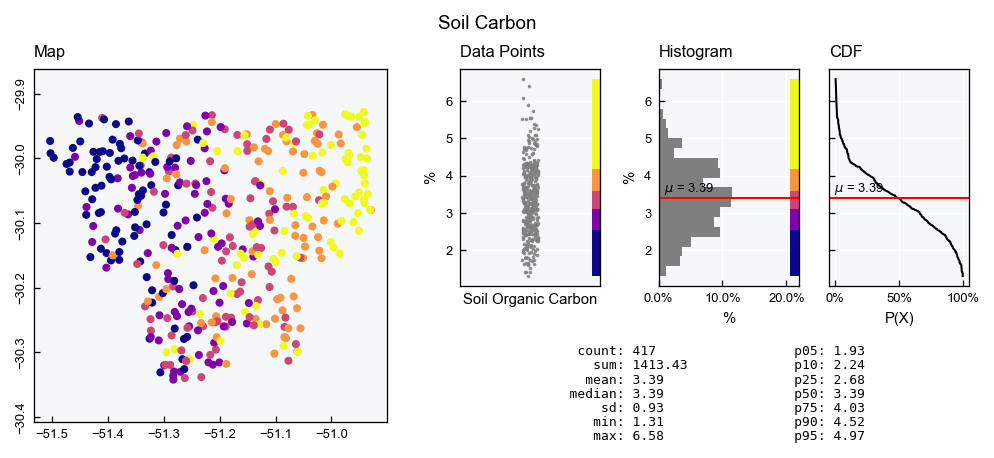

In [14]:
gv.view_specs["n_classes_cmap"] = 5
gv.view_specs["cmap"] = "plasma"
gv.view_specs["markersize_map"] = 15
gv.view()

## Adding the catchment

Other geometries go in the `layers_map` key, as a list with one dictionary per layer. The `data` key holds the geometries, in the same CRS as the points, and all other keys go to their `.plot()` method. Polygons and lines stay below the points, which are on the layer set by `zorder_map`:

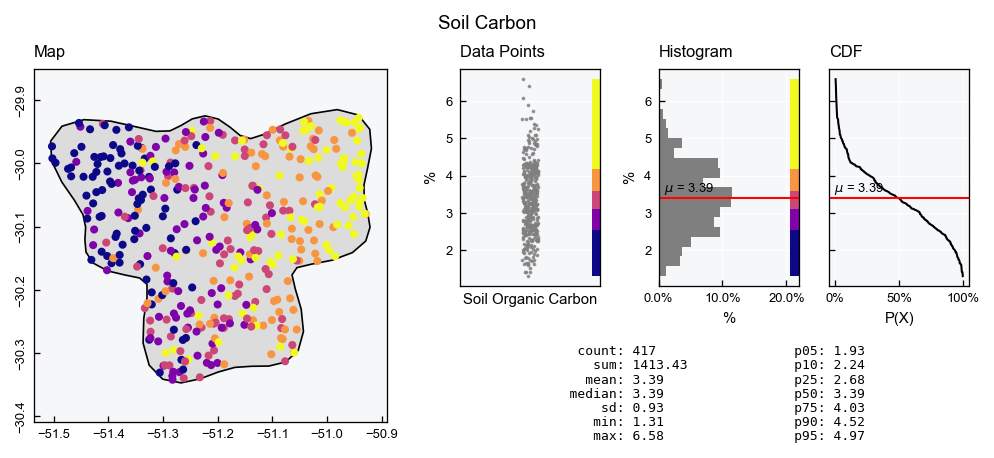

In [15]:
gv.view_specs["layers_map"] = [
    {"data": catchment, "facecolor": "gainsboro", "edgecolor": "black", "linewidth": 0.8},
]
gv.view()

## Loading from a file

The data usually comes from a file. Lets write both layers to a GeoPackage:

In [16]:
file_db = OUTPUT_DIR / "catchment.gpkg"
points.to_file(filename=file_db, layer="samples", driver="GPKG")
catchment.to_file(filename=file_db, layer="catchment", driver="GPKG")

The `.load_data()` method takes the file, the name of the layer and the name of the column of values, and gives the same table as `.set_data()`:

In [17]:
gv_file = GeoUnivar(name="Soil Carbon", alias="SOC")
gv_file.varname = "Soil Organic Carbon"
gv_file.units = "%"
gv_file.load_data(file_data=file_db, layer_name="samples", input_varfield="soc")
gv_file.data.head()

,v,geometry
0,3.770107,POINT (-51.20624 -30.24392)
1,1.750928,POINT (-51.42191 -30.01331)
2,5.514472,POINT (-50.94999 -29.93546)
3,3.417389,POINT (-51.32355 -30.2484)
4,2.367847,POINT (-51.25815 -30.27589)


Other layers, like the catchment, are read with `geopandas` itself:

In [18]:
catchment_file = gpd.read_file(filename=file_db, layer="catchment")
catchment_file

,name,geometry
0,Catchment,"POLYGON ((-50.92244 -30.1, -50.92667 -30.0779,..."


## Recap

- `GeoUnivar` is a `Univar` with a `GeoDataFrame` as data, and a map panel in its visual.
- `.set_data()` and `.load_data()` take the name of the column of values.
- `view_specs["layout"]` switches between `full` and `mini`.
- `scheme_cmap` defines the classes, as `equal` or `quantiles`, and `n_classes_cmap` sets how many. `cmap` sets the colors, and the `_map` keys set the map panel.
- `layers_map` adds a catchment or other geometries to the map.